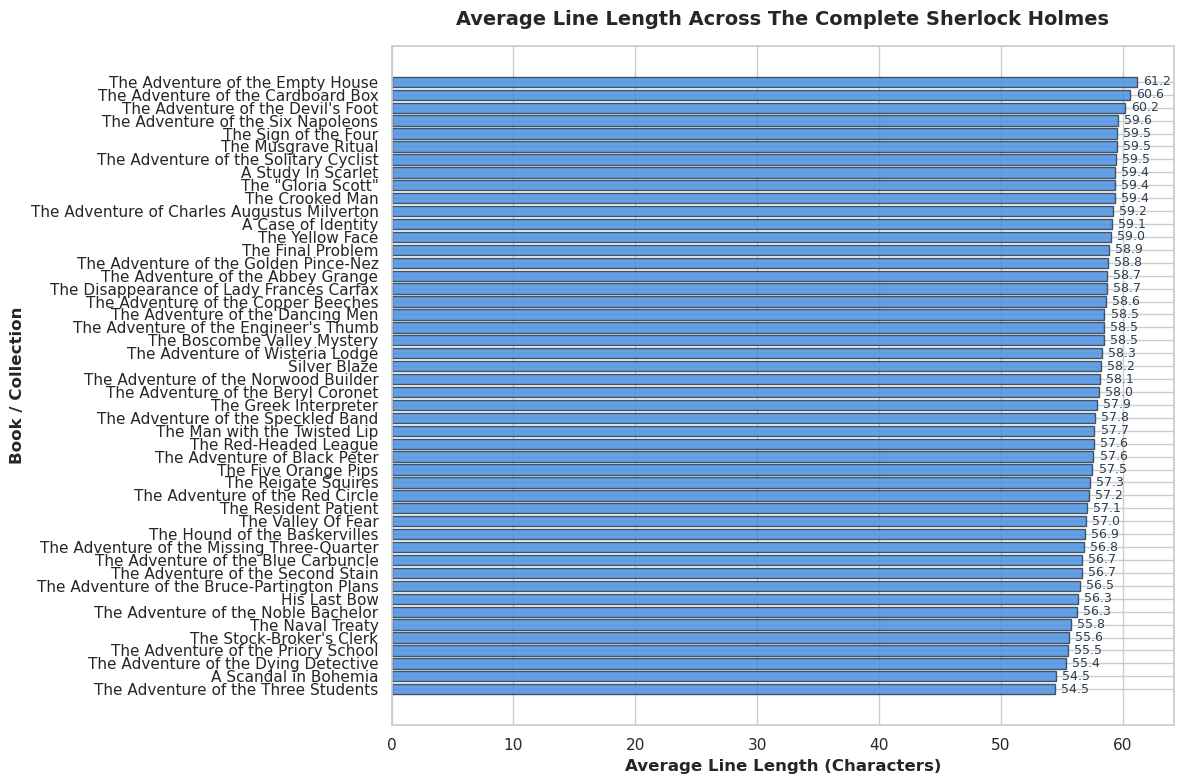

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the Sherlock Holmes dataset from GitHub
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-11-18/holmes.csv"
df = pd.read_csv(url)

# 2. Data Cleaning & Feature Engineering
# Drop rows with missing text and compute the character length of each line
df = df.dropna(subset=['text'])
df['line_length'] = df['text'].str.len()

# Calculate average line length per book and sort for clean visualization
avg_length = (
    df.groupby('book')['line_length'].mean().reset_index().sort_values(by='line_length', ascending=True)
)

# 3. Create the Visualization
plt.figure(figsize=(12, 8))
sns.set_theme(style='whitegrid')

bars = plt.barh(
    avg_length['book'], avg_length['line_length'], color='#4a90e2', edgecolor='#2c3e50', alpha=0.85
)

# Customize axes and titles
plt.xlabel('Average Line Length (Characters)', fontsize=12, fontweight='bold')
plt.ylabel('Book / Collection', fontsize=12, fontweight='bold')
plt.title(
    'Average Line Length Across The Complete Sherlock Holmes',
    fontsize=14,
    fontweight='bold',
    pad=15,
)

# Annotate bars with exact values
for bar in bars:
  width = bar.get_width()
  plt.text(
      width + 0.5,
      bar.get_y() + bar.get_height() / 2,
      f'{width:.1f}',
      va='center',
      ha='left',
      fontsize=9,
      color='#2c3e50',
  )

# Adjust layout and display chart
plt.tight_layout()
plt.show()